# 09 · Physics and Space Research

From deriving equations to simulating orbits, Python covers the whole loop of physical science: **SymPy**
does the algebra, **SciPy** solves what has no closed form, **NumPy** analyses signals, and **Astropy**,
the community library of astronomy, keeps units and constants right.

**You will learn**
1. Symbolic mathematics: derive a pendulum's equation of motion with SymPy
2. Numerical simulation: solve it with SciPy and see where the textbook approximation fails
3. Signal analysis: recover a pendulum's frequency with the Fourier transform
4. Units and constants with Astropy, and Kepler's third law checked on the real planets
5. Integrating an orbit and validating it with conservation of energy and angular momentum
6. Sky coordinates: converting between reference frames

## 1. Deriving the equation of motion symbolically
For a pendulum of length $L$ the Lagrangian is kinetic minus potential energy,
$\mathcal{L} = \tfrac12 m L^2 \dot\theta^2 + m g L \cos\theta$. The Euler-Lagrange equation gives the
motion; SymPy does the calculus.

In [1]:
import sympy as sp

t = sp.symbols("t")
m, g, L = sp.symbols("m g L", positive=True)
theta = sp.Function("theta")(t)
lagrangian = sp.Rational(1, 2) * m * L**2 * theta.diff(t)**2 + m * g * L * sp.cos(theta)
euler_lagrange = sp.diff(lagrangian.diff(theta.diff(t)), t) - lagrangian.diff(theta)
eq = sp.Eq(sp.solve(euler_lagrange, theta.diff(t, 2))[0], theta.diff(t, 2))
eq

Eq(-g*sin(theta(t))/L, Derivative(theta(t), (t, 2)))

In [2]:
# for small angles sin(θ) ≈ θ and the equation has a closed-form solution with period 2π√(L/g)
theta0 = sp.symbols("theta0")
small = sp.dsolve(theta.diff(t, 2) + g / L * theta, theta, ics={theta.subs(t, 0): theta0, theta.diff(t).subs(t, 0): 0})
print(small)
print("small-angle period:", sp.simplify(2 * sp.pi / sp.sqrt(g / L)))

Eq(theta(t), theta0*cos(sqrt(g)*t/sqrt(L)))
small-angle period: 2*pi*sqrt(L)/sqrt(g)


## 2. Simulating the full pendulum
The real equation $\ddot\theta = -\tfrac{g}{L}\sin\theta$ has no elementary solution. `scipy.integrate.solve_ivp`
integrates it numerically. Comparing with the small-angle formula shows when the textbook approximation
is good enough.

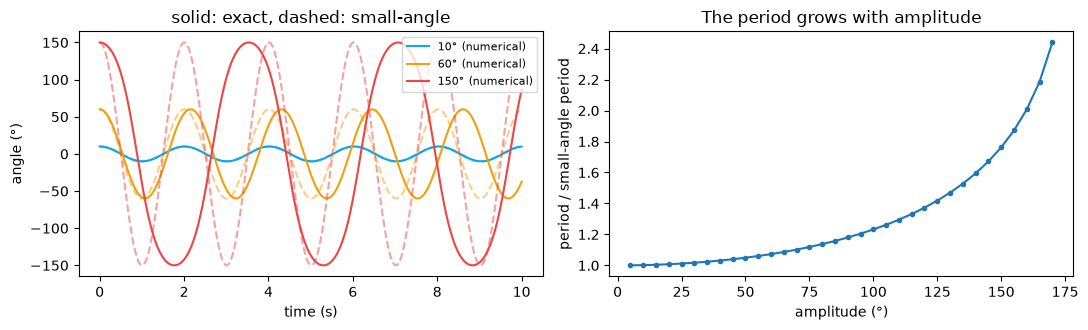

error of the small-angle period: 0.19% at 10°, 7.3% at 60°


In [3]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

G, LEN = 9.81, 1.0
def pendulum(t, y):
    th, om = y
    return [om, -G / LEN * np.sin(th)]

t_eval = np.linspace(0, 10, 4000)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for amp_deg, color in [(10, "#0ea5e9"), (60, "#f59e0b"), (150, "#ef4444")]:
    amp = np.radians(amp_deg)
    sol = solve_ivp(pendulum, (0, 10), [amp, 0], t_eval=t_eval, rtol=1e-9, atol=1e-9)
    ax[0].plot(sol.t, np.degrees(sol.y[0]), color=color, label=f"{amp_deg}° (numerical)")
    ax[0].plot(t_eval, amp_deg * np.cos(np.sqrt(G / LEN) * t_eval), "--", color=color, alpha=.5)
ax[0].set_xlabel("time (s)"); ax[0].set_ylabel("angle (°)"); ax[0].legend(fontsize=8); ax[0].set_title("solid: exact, dashed: small-angle")

# period as a function of amplitude, measured from the simulation
amps = np.radians(np.linspace(5, 170, 34))
def period(amp):
    s = solve_ivp(pendulum, (0, 20), [amp, 0], events=lambda t, y: y[1], rtol=1e-10, atol=1e-10, dense_output=True)
    crossings = [tc for tc in s.t_events[0] if tc > 1e-6]
    return 2 * crossings[0]              # velocity is zero at each turning point, half a period apart
T0 = 2 * np.pi * np.sqrt(LEN / G)
ax[1].plot(np.degrees(amps), [period(a) / T0 for a in amps], "o-", ms=3)
ax[1].set_xlabel("amplitude (°)"); ax[1].set_ylabel("period / small-angle period"); ax[1].set_title("The period grows with amplitude")
plt.tight_layout(); plt.show()
print(f"error of the small-angle period: {100 * (period(np.radians(10)) / T0 - 1):.2f}% at 10°, "
      f"{100 * (period(np.radians(60)) / T0 - 1):.1f}% at 60°")

## 3. Finding the frequency with a Fourier transform
Experiments give noisy measurements, not equations. The fast Fourier transform (FFT) finds the dominant
frequency in a noisy signal.

dominant frequency 0.4833 Hz -> period 2.069 s (simulation: 2.041 s)
frequency resolution of a 60 s recording: 0.0167 Hz, so the estimate is exact to within one frequency bin; record longer to resolve finer


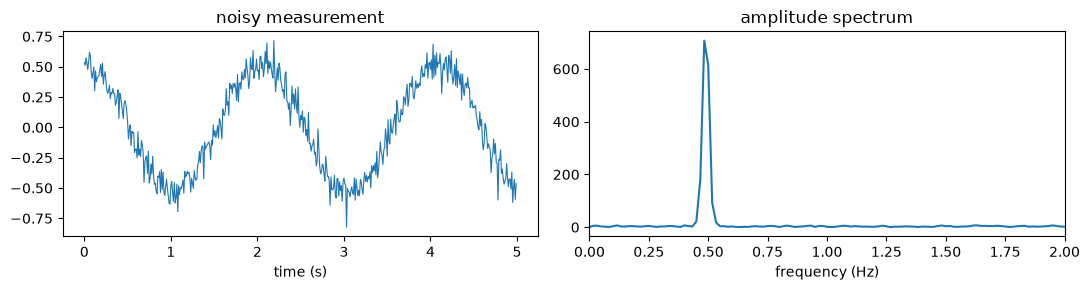

In [4]:
rng = np.random.default_rng(0)
amp = np.radians(30)
fs, duration = 100, 60                            # 100 samples per second, one minute
tt = np.arange(0, duration, 1 / fs)
signal = solve_ivp(pendulum, (0, duration), [amp, 0], t_eval=tt, rtol=1e-9).y[0]
measured = signal + rng.normal(0, 0.08, tt.size)   # sensor noise

spectrum = np.abs(np.fft.rfft(measured * np.hanning(tt.size)))
freqs = np.fft.rfftfreq(tt.size, 1 / fs)
f_peak = freqs[np.argmax(spectrum[1:]) + 1]
print(f"dominant frequency {f_peak:.4f} Hz -> period {1 / f_peak:.3f} s (simulation: {period(amp):.3f} s)")
print(f"frequency resolution of a {duration} s recording: {1 / duration:.4f} Hz, so the estimate is exact "
      "to within one frequency bin; record longer to resolve finer")

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(tt[:500], measured[:500], lw=.8); ax[0].set_xlabel("time (s)"); ax[0].set_title("noisy measurement")
ax[1].plot(freqs, spectrum); ax[1].set_xlim(0, 2); ax[1].set_xlabel("frequency (Hz)"); ax[1].set_title("amplitude spectrum")
plt.tight_layout(); plt.show()

## 4. Units, constants and Kepler's third law with Astropy
Unit mistakes have destroyed spacecraft. Astropy attaches units to numbers, converts them, and refuses
to add incompatible quantities. Kepler's third law says $T^2 = \frac{4\pi^2}{G M_\odot} a^3$: the square of
a planet's orbital period grows with the cube of its distance from the Sun.

In [5]:
import astropy.units as u
from astropy import constants as const

print(const.G, "\n", const.M_sun, "\n", (1 * u.au).to(u.km), "|", (1 * u.lyr).to(u.au))
try:
    1 * u.m + 1 * u.s
except u.UnitConversionError as e:
    print("refused:", e)

# semi-major axes (AU) and observed sidereal orbital periods (days)
planets = {"Mercury": (0.3871, 87.969), "Venus": (0.7233, 224.701), "Earth": (1.0000, 365.256),
           "Mars": (1.5237, 686.980), "Jupiter": (5.2034, 4332.59), "Saturn": (9.5371, 10759.22),
           "Uranus": (19.191, 30688.5), "Neptune": (30.069, 60182.0)}
print(f"\n{'planet':<9}{'observed (yr)':>14}{'Kepler (yr)':>13}{'error':>9}")
for name, (a_au, t_days) in planets.items():
    predicted = (2 * np.pi * np.sqrt((a_au * u.au) ** 3 / (const.G * const.M_sun))).to(u.yr)
    observed = (t_days * u.day).to(u.yr)
    print(f"{name:<9}{observed.value:>14.3f}{predicted.value:>13.3f}{100 * (predicted / observed - 1).value:>8.2f}%")

  Name   = Gravitational constant
  Value  = 6.6743e-11
  Uncertainty  = 1.5e-15
  Unit  = m3 / (kg s2)
  Reference = CODATA 2022 
   Name   = Solar mass
  Value  = 1.988409870698051e+30
  Uncertainty  = 4.468805426856864e+25
  Unit  = kg
  Reference = IAU 2015 Resolution B 3 + CODATA 2022 
 149597870.7 km | 63241.07708426628 AU
refused: Can only apply 'add' function to quantities with compatible dimensions

planet    observed (yr)  Kepler (yr)    error
Mercury           0.241        0.241    0.00%
Venus             0.615        0.615   -0.01%
Earth             1.000        1.000    0.00%
Mars              1.881        1.881    0.00%
Jupiter          11.862       11.870    0.06%
Saturn           29.457       29.453   -0.01%
Uranus           84.021       84.073    0.06%
Neptune         164.769      164.887    0.07%


## 5. Integrating an orbit, checked by conservation laws
We launch a satellite into an elliptical Earth orbit and integrate Newton's law of gravitation. A
numerical solution is only trustworthy if it respects the physics: **energy** and **angular momentum**
must stay constant. Comparing a sloppy and a precise integration shows why tolerances matter.

rtol=0.001: 56 steps, relative energy drift 2.5e-02, angular momentum drift 1.1e-02


rtol=1e-10: 1093 steps, relative energy drift 7.8e-10, angular momentum drift 3.0e-10
after one day the loose integration places the satellite 3,834 km from where it really is


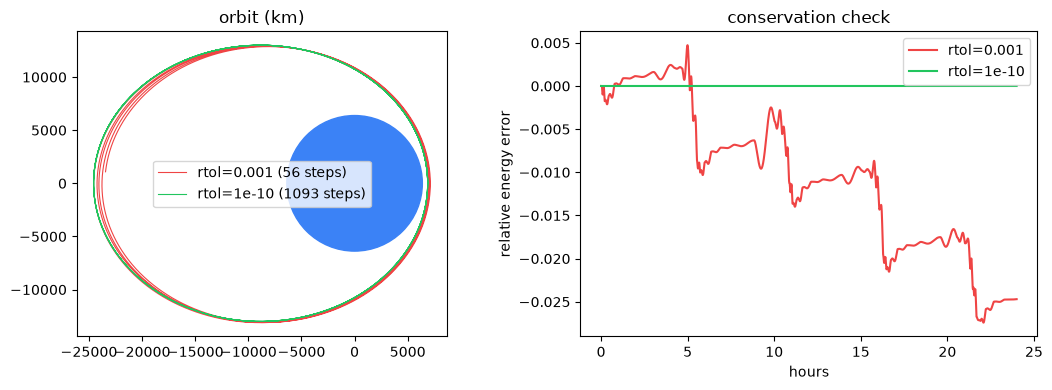

In [6]:
mu = (const.G * const.M_earth).to(u.km**3 / u.s**2).value      # Earth's gravitational parameter, km^3/s^2
r0 = 6378 + 500                                                  # 500 km altitude, km
v_circ = np.sqrt(mu / r0)
state0 = [r0, 0, 0, 1.25 * v_circ]                               # 25% faster than circular: an ellipse

def two_body(t, s):
    x, y, vx, vy = s
    r3 = (x * x + y * y) ** 1.5
    return [vx, vy, -mu * x / r3, -mu * y / r3]

T_orbit = 24 * 3600                                               # one day, about 4.4 orbits
tt = np.linspace(0, T_orbit, 4000)
def run(rtol):
    sol = solve_ivp(two_body, (0, T_orbit), state0, rtol=rtol, atol=min(rtol * 1e-3, 1e-6), dense_output=True)
    x, y, vx, vy = sol.sol(tt)                                    # evaluate the solution on a fine grid
    energy = 0.5 * (vx**2 + vy**2) - mu / np.hypot(x, y)
    h = x * vy - y * vx
    return sol, (x, y), energy, h

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
final = {}
for rtol, color in [(1e-3, "#ef4444"), (1e-10, "#22c55e")]:
    sol, (x, y), energy, h = run(rtol)
    final[rtol] = np.array([x[-1], y[-1]])
    ax[0].plot(x, y, color=color, lw=.8, label=f"rtol={rtol:g} ({sol.t.size} steps)")
    ax[1].plot(tt / 3600, (energy - energy[0]) / abs(energy[0]), color=color, label=f"rtol={rtol:g}")
    print(f"rtol={rtol:g}: {sol.t.size} steps, relative energy drift {abs(energy[-1] / energy[0] - 1):.1e}, "
          f"angular momentum drift {abs(h[-1] / h[0] - 1):.1e}")
print(f"after one day the loose integration places the satellite {np.linalg.norm(final[1e-3] - final[1e-10]):,.0f} km "
      "from where it really is")
ax[0].add_patch(plt.Circle((0, 0), 6378, color="#3b82f6")); ax[0].set_aspect("equal"); ax[0].legend(); ax[0].set_title("orbit (km)")
ax[1].set_xlabel("hours"); ax[1].set_ylabel("relative energy error"); ax[1].legend(); ax[1].set_title("conservation check")
plt.tight_layout(); plt.show()

## 6. Sky coordinates
Astronomers describe positions in different frames: equatorial (right ascension, declination), galactic,
ecliptic. Astropy converts between them.

In [7]:
from astropy.coordinates import SkyCoord

targets = {"Sirius": ("06h45m08.9s", "-16d42m58s"), "Betelgeuse": ("05h55m10.3s", "+07d24m25s"),
           "Andromeda galaxy (M31)": ("00h42m44.3s", "+41d16m09s")}
for name, (ra, dec) in targets.items():
    c = SkyCoord(ra, dec, frame="icrs")
    gal = c.galactic
    print(f"{name:<24} RA {c.ra.deg:7.2f}°  Dec {c.dec.deg:6.2f}°  ->  galactic l {gal.l.deg:7.2f}°  b {gal.b.deg:6.2f}°")
sirius, betel = SkyCoord(*targets["Sirius"]), SkyCoord(*targets["Betelgeuse"])
print("angular separation Sirius-Betelgeuse:", sirius.separation(betel).to_string(unit=u.deg, precision=1))

Sirius                   RA  101.29°  Dec -16.72°  ->  galactic l  227.23°  b  -8.89°
Betelgeuse               RA   88.79°  Dec   7.41°  ->  galactic l  199.79°  b  -8.96°
Andromeda galaxy (M31)   RA   10.68°  Dec  41.27°  ->  galactic l  121.17°  b -21.57°
angular separation Sirius-Betelgeuse: 27d06m15.8s


## Libraries worth knowing
| Area | Libraries |
|---|---|
| symbolic maths | SymPy |
| simulation, ODEs, optimisation | SciPy, JAX (differentiable simulation) |
| astronomy | Astropy, astroquery (archive queries), Skyfield (precise ephemerides), poliastro/hapsira (astrodynamics), lightkurve (Kepler/TESS light curves) |
| particle and nuclear physics | uproot, awkward-array, scikit-hep |
| fluids, finite elements | FEniCS, PyClaw |
| quantum computing | Qiskit, Cirq, PennyLane |

## Exercises
1. Add air resistance (a term $-c\,\dot\theta$) to the pendulum and measure how the amplitude decays.
2. Increase the launch speed to 1.45 times circular. Is the orbit still bound? Check the sign of the energy.
3. Use the planets table to fit $\log T$ against $\log a$ with NumPy and recover the exponent 3/2.